# PROV: Initial Analysis

* Python imports

In [1]:
# Standard library imports
import math
from collections import defaultdict, OrderedDict

import ipywidgets as widgets
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import networkx as nx
# Third-party imports
import numpy as np
import pandas as pd
import squarify
from IPython.display import clear_output
from SPARQLWrapper import JSON
from ipywidgets import Image

from kieker_analysis.sparql.client import kieker_client

* Configure database endpoint and helper function

In [2]:
def runQuery(query):
    kieker_client.setQuery(query)
    kieker_client.setReturnFormat(JSON)
    return kieker_client.query().convert()

* Set project

In [3]:
project = "kieker-monitoring/kieker"

## Section 2: Github User Analysis - Issues

Analyse user activity by looking at their contributions to issues.

* Run query to find all actions related to issues and build a DAG

In [4]:
# Query for all issues and how was involved with them. Build a graph to store agents(node), issues(node) and associations(edges)

query = """
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX github2prov: <http://purl.org/github2prov/>

SELECT DISTINCT ?i ?a WHERE {
 {
    ?e prov:wasAssociatedWith ?a.
    ?e a prov:Activity.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
  }}
"""

results = runQuery(query)

# Parse results to extract agent-entity and agent-activity relationships
issues_by_agent = defaultdict(set)
issue_participants = defaultdict(set)
issues = set()
activities = set()
agents = set()

bindings = results['results']['bindings']

# Parse your SPARQL results
for b in bindings:
    issue = b['i']['value']
    agent = b['a']['value']

    issues_by_agent[agent].add(issue)
    issue_participants[issue].add(agent)
    agents.add(agent)
    issues.add(issue)

# Create undirected graph of agent collaboration based on shared entities
G = nx.Graph()

# Add agent nodes
for agent in agents:
    G.add_node(agent, type='agent')

# Add entity nodes
for issue in issues:
    if len(issue_participants[issue]) > 1:
        G.add_node(issue, type='issue')

# Add edges between agent entity (wasAttributedTo)
for agent, issues in issues_by_agent.items():
    for i in issues:
        if len(issue_participants[i]) > 1:
            G.add_edge(agent, i, relation='wasAssociatedWith')

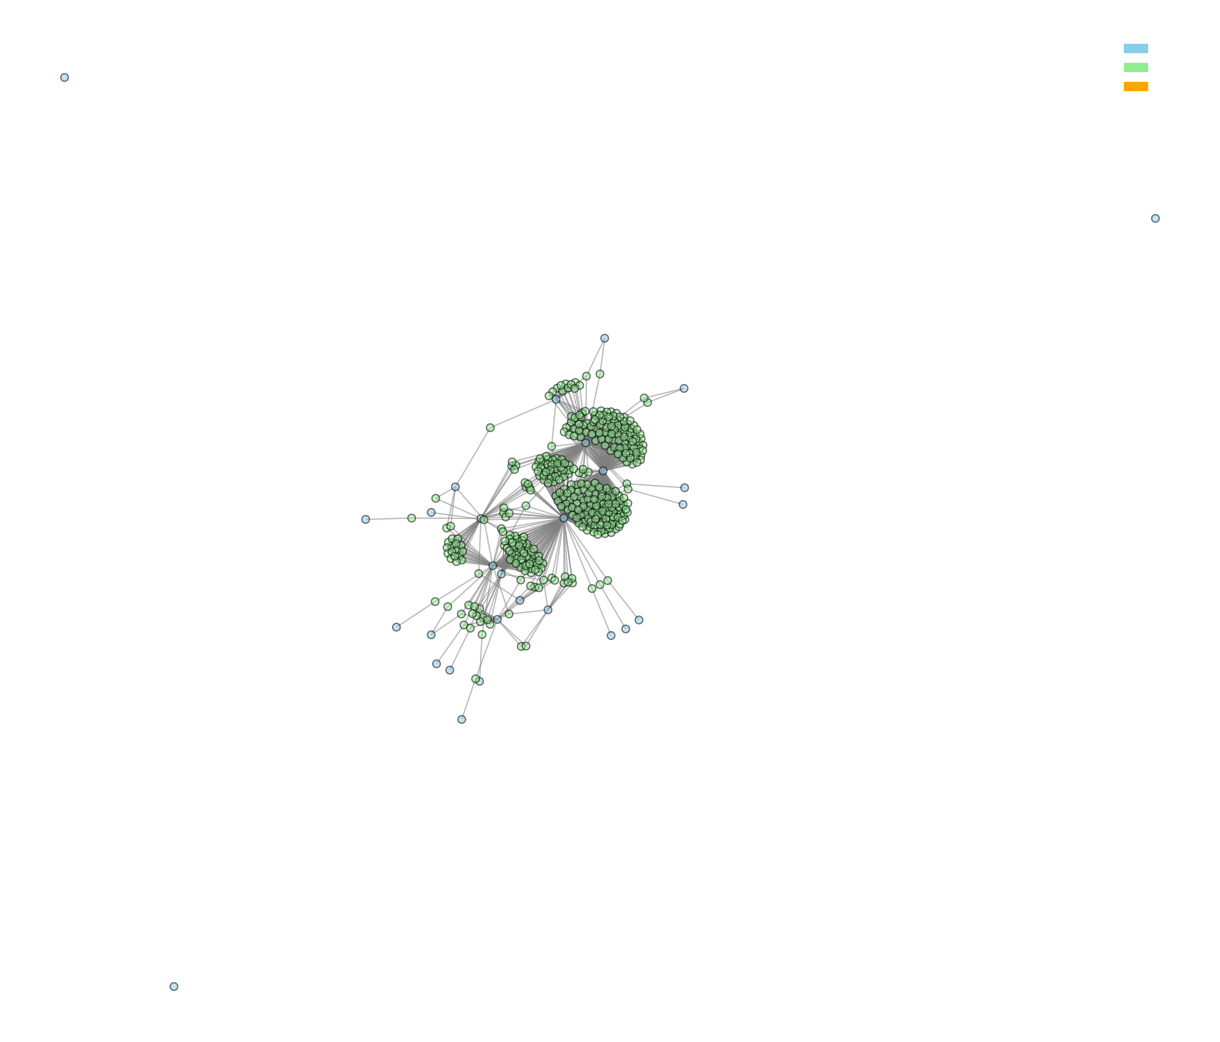

Saved to users_issues.png


In [5]:
# Render a graph
# Map node types to colors
color_map = {
    'agent': 'skyblue',
    'issue': 'lightgreen',
    'activity': 'orange'
}

# Create list of colors based on node type
node_colors = [color_map.get(G.nodes[node].get('type', ''), 'black') for node in G.nodes]

# Optional: relabel nodes (especially if they are URIs)
labels = {node: node.split('/')[-1] for node in G.nodes()}
edge_weights = nx.get_edge_attributes(G, 'weight')
# Plot and save
plt.figure(figsize=(12, 10))

pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=False, node_size=30, edge_color='gray', node_color=node_colors, edgecolors='black',
        linewidths=1, alpha=0.5)
plt.title("Users interacting on Issues")

# Create legend patches
legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
plt.legend(handles=legend_patches, loc='best', fontsize='small', frameon=False)

plt.savefig("users_issues.png", dpi=300)
plt.show()
plt.close()

print("Saved to users_issues.png")

* Build graphs for indivdual users, showing who they've interacted with

In [6]:
agent_graphs = {}

for agent in agents:
    G = nx.Graph()

    # Add the agent of interest only once
    G.add_node(agent, type='agent_of_interest')

    # Add issues related to this agent
    issues = issues_by_agent.get(agent, set())
    for issue in issues:
        G.add_node(issue, type='issue')
        G.add_edge(agent, issue, relation="wasAssociatedWith")

        for a in issue_participants[issue]:
            if a != agent:
                if not G.has_node(a):
                    G.add_node(a, type='agent')  # Add other agents
                G.add_edge(a, issue, relation='wasAssociatedWith')

    # Store the graph
    agent_graphs[agent] = G

* Calculate statistics for the users

In [7]:
# Collect stats for each agent
stats_data = []

for agent, G in agent_graphs.items():
    num_issues = sum(1 for n, d in G.nodes(data=True) if d['type'] == 'issue')
    num_other_agents = sum(1 for n, d in G.nodes(data=True) if d['type'] == 'agent')
    degree_agent = G.degree(agent)

    issue_nodes = [n for n, d in G.nodes(data=True) if d['type'] == 'issue']
    avg_participants_per_issue = (
        np.mean([G.degree(n) for n in issue_nodes]) if issue_nodes else 0
    )

    density = nx.density(G)
    clustering = nx.average_clustering(G)

    stats_data.append({
        "Agent": agent.split("/")[-1],
        "# Issues": num_issues,
        "# Co-Agents": num_other_agents,
        "Agent Degree": degree_agent,
        "Avg Participants / Issue": round(avg_participants_per_issue, 2),
        "Graph Density": round(density, 3),
        "Avg Clustering": round(clustering, 3),
    })

# Create pandas DataFrame
stats_df = pd.DataFrame(stats_data)

# Display the table, sorted by # Issues (or any other metric)
stats_df.sort_values(by="# Issues", ascending=False).reset_index(drop=True)

,Agent,# Issues,# Co-Agents,Agent Degree,Avg Participants / Issue,Graph Density,Avg Clustering
0,rju,2386,16,2386,1.10,0.001,0.0
1,dependabot,235,3,235,1.89,0.016,0.0
2,DaGeRe,195,9,195,1.94,0.018,0.0
3,duelle,114,13,114,1.70,0.024,0.0
4,ChristianWulf,63,8,63,1.40,0.034,0.0
5,avanhoorn,53,6,53,1.83,0.055,0.0
6,SoerenHenning,27,4,27,2.07,0.113,0.0
7,shinhyungyang,21,5,21,2.24,0.134,0.0
8,kieker-ci,9,5,9,1.78,0.152,0.0
9,holgerknoche,9,4,9,2.22,0.220,0.0


* Example of text that we could generate about github users
* TODO needs refining and justification of numbers
* TODO use the timeframe of the project for more context, i.e. 10 issues is a lot for 6 months, but not over 10 years

In [8]:
def generate_summary_text(agent, G):
    agent_name = agent.split('/')[-1]
    agent_name = f"**{agent.split('/')[-1]}**"
    num_issues = sum(1 for _, d in G.nodes(data=True) if d.get('type') == 'issue')
    num_co_agents = sum(1 for _, d in G.nodes(data=True) if d.get('type') == 'agent')
    degree_agent = G.degree(agent)
    density = nx.density(G)
    clustering = nx.average_clustering(G)

    # Engagement level based on number of issues
    if num_issues > 10:
        engagement_text = (
            f"{agent_name} has been extensively involved in {num_issues} issues, "
            "indicating strong commitment and active participation across various projects."
        )
    elif num_issues > 3:
        engagement_text = (
            f"{agent_name} has contributed to a moderate number of issues ({num_issues}), "
            "showing consistent involvement but with room to expand their scope."
        )
    else:
        engagement_text = (
            f"{agent_name}'s involvement includes {num_issues} issues, suggesting a focused or emerging participation."
        )

    # Collaboration nuance based on number of co-agents
    if num_co_agents > 10:
        collab_text = (
            f"Collaboration with over {num_co_agents} colleagues reflects an ability to engage with diverse teams, "
            "though the depth of these interactions may vary."
        )
    elif num_co_agents > 3:
        collab_text = (
            f"Collaborating with {num_co_agents} peers demonstrates capability to work within small to medium teams."
        )
    else:
        collab_text = (
            f"With a small set of collaborators ({num_co_agents}), {agent_name} may be focused on specialized or individual tasks."
        )

    # Influence based on degree
    if degree_agent > 8:
        influence_text = (
            f"Having {degree_agent} direct connections, {agent_name} likely serves as a key contributor or connector within the network."
        )
    elif degree_agent > 3:
        influence_text = (
            f"{agent_name} maintains a moderate number of connections ({degree_agent}), indicating steady involvement."
        )
    else:
        influence_text = (
            f"Limited direct connections ({degree_agent}) suggest {agent_name} plays a more peripheral or specialized role."
        )

    # Network density interpretation
    if density > 0.1:
        density_text = (
            "The network's relatively high interconnectedness may facilitate communication and collaboration, "
            f"potentially benefiting {agent_name}'s projects."
        )
    else:
        density_text = (
            "Lower network density indicates collaborations may be more dispersed or segmented, "
            "which can reflect specialization or working across different groups."
        )

    # Clustering coefficient nuance
    if clustering > 0.05:
        clustering_text = (
            f"Clusters within the network suggest {agent_name} participates in close-knit teams, fostering effective group dynamics."
        )
    else:
        clustering_text = (
            f"Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
        )

    summary = (
        f"{engagement_text} {collab_text} {influence_text} "
        f"{density_text} {clustering_text}"
    )
    return summary


# Example usage for all agents
summary_list = [
    {"Agent": agent.split('/')[-1], "Summary": generate_summary_text(agent, G)}
    for agent, G in agent_graphs.items()
]

summary_df = pd.DataFrame(summary_list)
summary_df.style.set_properties(subset=['Summary'], **{'text-align': 'left'})


,Agent,Summary
0,DaGeRe,"**DaGeRe** has been extensively involved in 195 issues, indicating strong commitment and active participation across various projects. Collaborating with 9 peers demonstrates capability to work within small to medium teams. Having 195 direct connections, **DaGeRe** likely serves as a key contributor or connector within the network. Lower network density indicates collaborations may be more dispersed or segmented, which can reflect specialization or working across different groups. Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
1,cbkurz,"**cbkurz**'s involvement includes 1 issues, suggesting a focused or emerging participation. With a small set of collaborators (1), **cbkurz** may be focused on specialized or individual tasks. Limited direct connections (1) suggest **cbkurz** plays a more peripheral or specialized role. The network's relatively high interconnectedness may facilitate communication and collaboration, potentially benefiting **cbkurz**'s projects. Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
2,ChristianStier,"**ChristianStier**'s involvement includes 1 issues, suggesting a focused or emerging participation. With a small set of collaborators (2), **ChristianStier** may be focused on specialized or individual tasks. Limited direct connections (1) suggest **ChristianStier** plays a more peripheral or specialized role. The network's relatively high interconnectedness may facilitate communication and collaboration, potentially benefiting **ChristianStier**'s projects. Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
3,czirkelbach,"**czirkelbach**'s involvement includes 1 issues, suggesting a focused or emerging participation. With a small set of collaborators (2), **czirkelbach** may be focused on specialized or individual tasks. Limited direct connections (1) suggest **czirkelbach** plays a more peripheral or specialized role. The network's relatively high interconnectedness may facilitate communication and collaboration, potentially benefiting **czirkelbach**'s projects. Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
4,aaschmid,"**aaschmid**'s involvement includes 2 issues, suggesting a focused or emerging participation. With a small set of collaborators (2), **aaschmid** may be focused on specialized or individual tasks. Limited direct connections (2) suggest **aaschmid** plays a more peripheral or specialized role. The network's relatively high interconnectedness may facilitate communication and collaboration, potentially benefiting **aaschmid**'s projects. Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
5,SoerenHenning,"**SoerenHenning** has been extensively involved in 27 issues, indicating strong commitment and active participation across various projects. Collaborating with 4 peers demonstrates capability to work within small to medium teams. Having 27 direct connections, **SoerenHenning** likely serves as a key contributor or connector within the network. The network's relatively high interconnectedness may facilitate communication and collaboration, potentially benefiting **SoerenHenning**'s projects. Lower clustering hints at involvement across distinct groups or projects, highlighting adaptability to different contexts."
6,marius,"**marius**'s involvement includes 1 issues, suggesting a focused or emerging participation. With a small set of collaborators (1), **marius** may be focused on specialized or individual tasks. Limited direct connections (1) suggest **marius** plays a more peripheral or specialized role. The network's relatively high interconnectedness may facilitate communication and collaboration

## Section 2: Individual Github User Anaylsis


* Example of individual, use the dropdown to select a specific individual

In [11]:
# Code to set up an graph and an interactive dropdown menu

# Node color map
color_map = {
    'agent': 'blue',
    'issue': 'limegreen',
    'agent_of_interest': 'coral'
}


# Node colors

def do_graph(selected_agent_key):
    clear_output(wait=True)

    if not selected_agent_key:
        print("Please select an agent.")
        return

    # Get the graph
    G = agent_graphs[selected_agent_key]
    selected_agent_name = selected_agent_key.split("/")[-1]

    # Prepare the plot
    fig, ax = plt.subplots(figsize=(6, 8))  # Size tuned for single plot

    node_colors = [color_map.get(G.nodes[node].get('type', ''), 'black') for node in G.nodes]

    # Graph layout
    pos = nx.spring_layout(G)

    # Labels for agents
    agent_labels = {
        node: node.split('/')[-1]
        for node in G.nodes
        if G.nodes[node].get('type') in ['agent', 'agent_of_interest']
    }

    # Shift label positions
    label_pos = {node: (x, y - 0.016) for node, (x, y) in pos.items() if node in agent_labels}

    # Draw graph
    nx.draw(G, pos, ax=ax, with_labels=False, node_size=60, edge_color='gray', font_size=14,
            node_color=node_colors, edgecolors='black', linewidths=1, alpha=0.8)

    nx.draw_networkx_labels(G, pos, labels=agent_labels, font_size=12, ax=ax)

    # Add title
    ax.set_title(f"GitHub name: {selected_agent_name}", fontsize=16)
    ax.axis('off')

    # Summary text
    summary = generate_summary_text(selected_agent_key, G)

    # Add summary box *below* the graph in figure coordinates
    plt.subplots_adjust(bottom=0.3)  # Make room for summary text
    fig.text(0.1, 0.02, summary, wrap=True, fontsize=10, ha='left', va='bottom',
             bbox=dict(facecolor='white', alpha=0.9, edgecolor='gray', boxstyle='round,pad=0.4'))

    # Add legend
    legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
    fig.legend(handles=legend_patches, loc='lower center', ncol=len(color_map), fontsize='medium', frameon=False)

    # Save and display
    plt.savefig(f"{selected_agent_name}_graph.png", dpi=300)
    plt.show()


agents = {a.split('/')[-1]: a for a in agent_graphs.keys()}

dropdown = widgets.Dropdown(
    options={'-- Select an Agent --': None, **agents},
    description='User:',
    disabled=False,
)
widgets.interact(do_graph, selected_agent_key=dropdown);


interactive(children=(Dropdown(description='User:', options={'-- Select an Agent --': None, 'DaGeRe': 'https:/…

* Displays all users connections over issues centered around an individual user.

Saved to all_agent_graphs.png


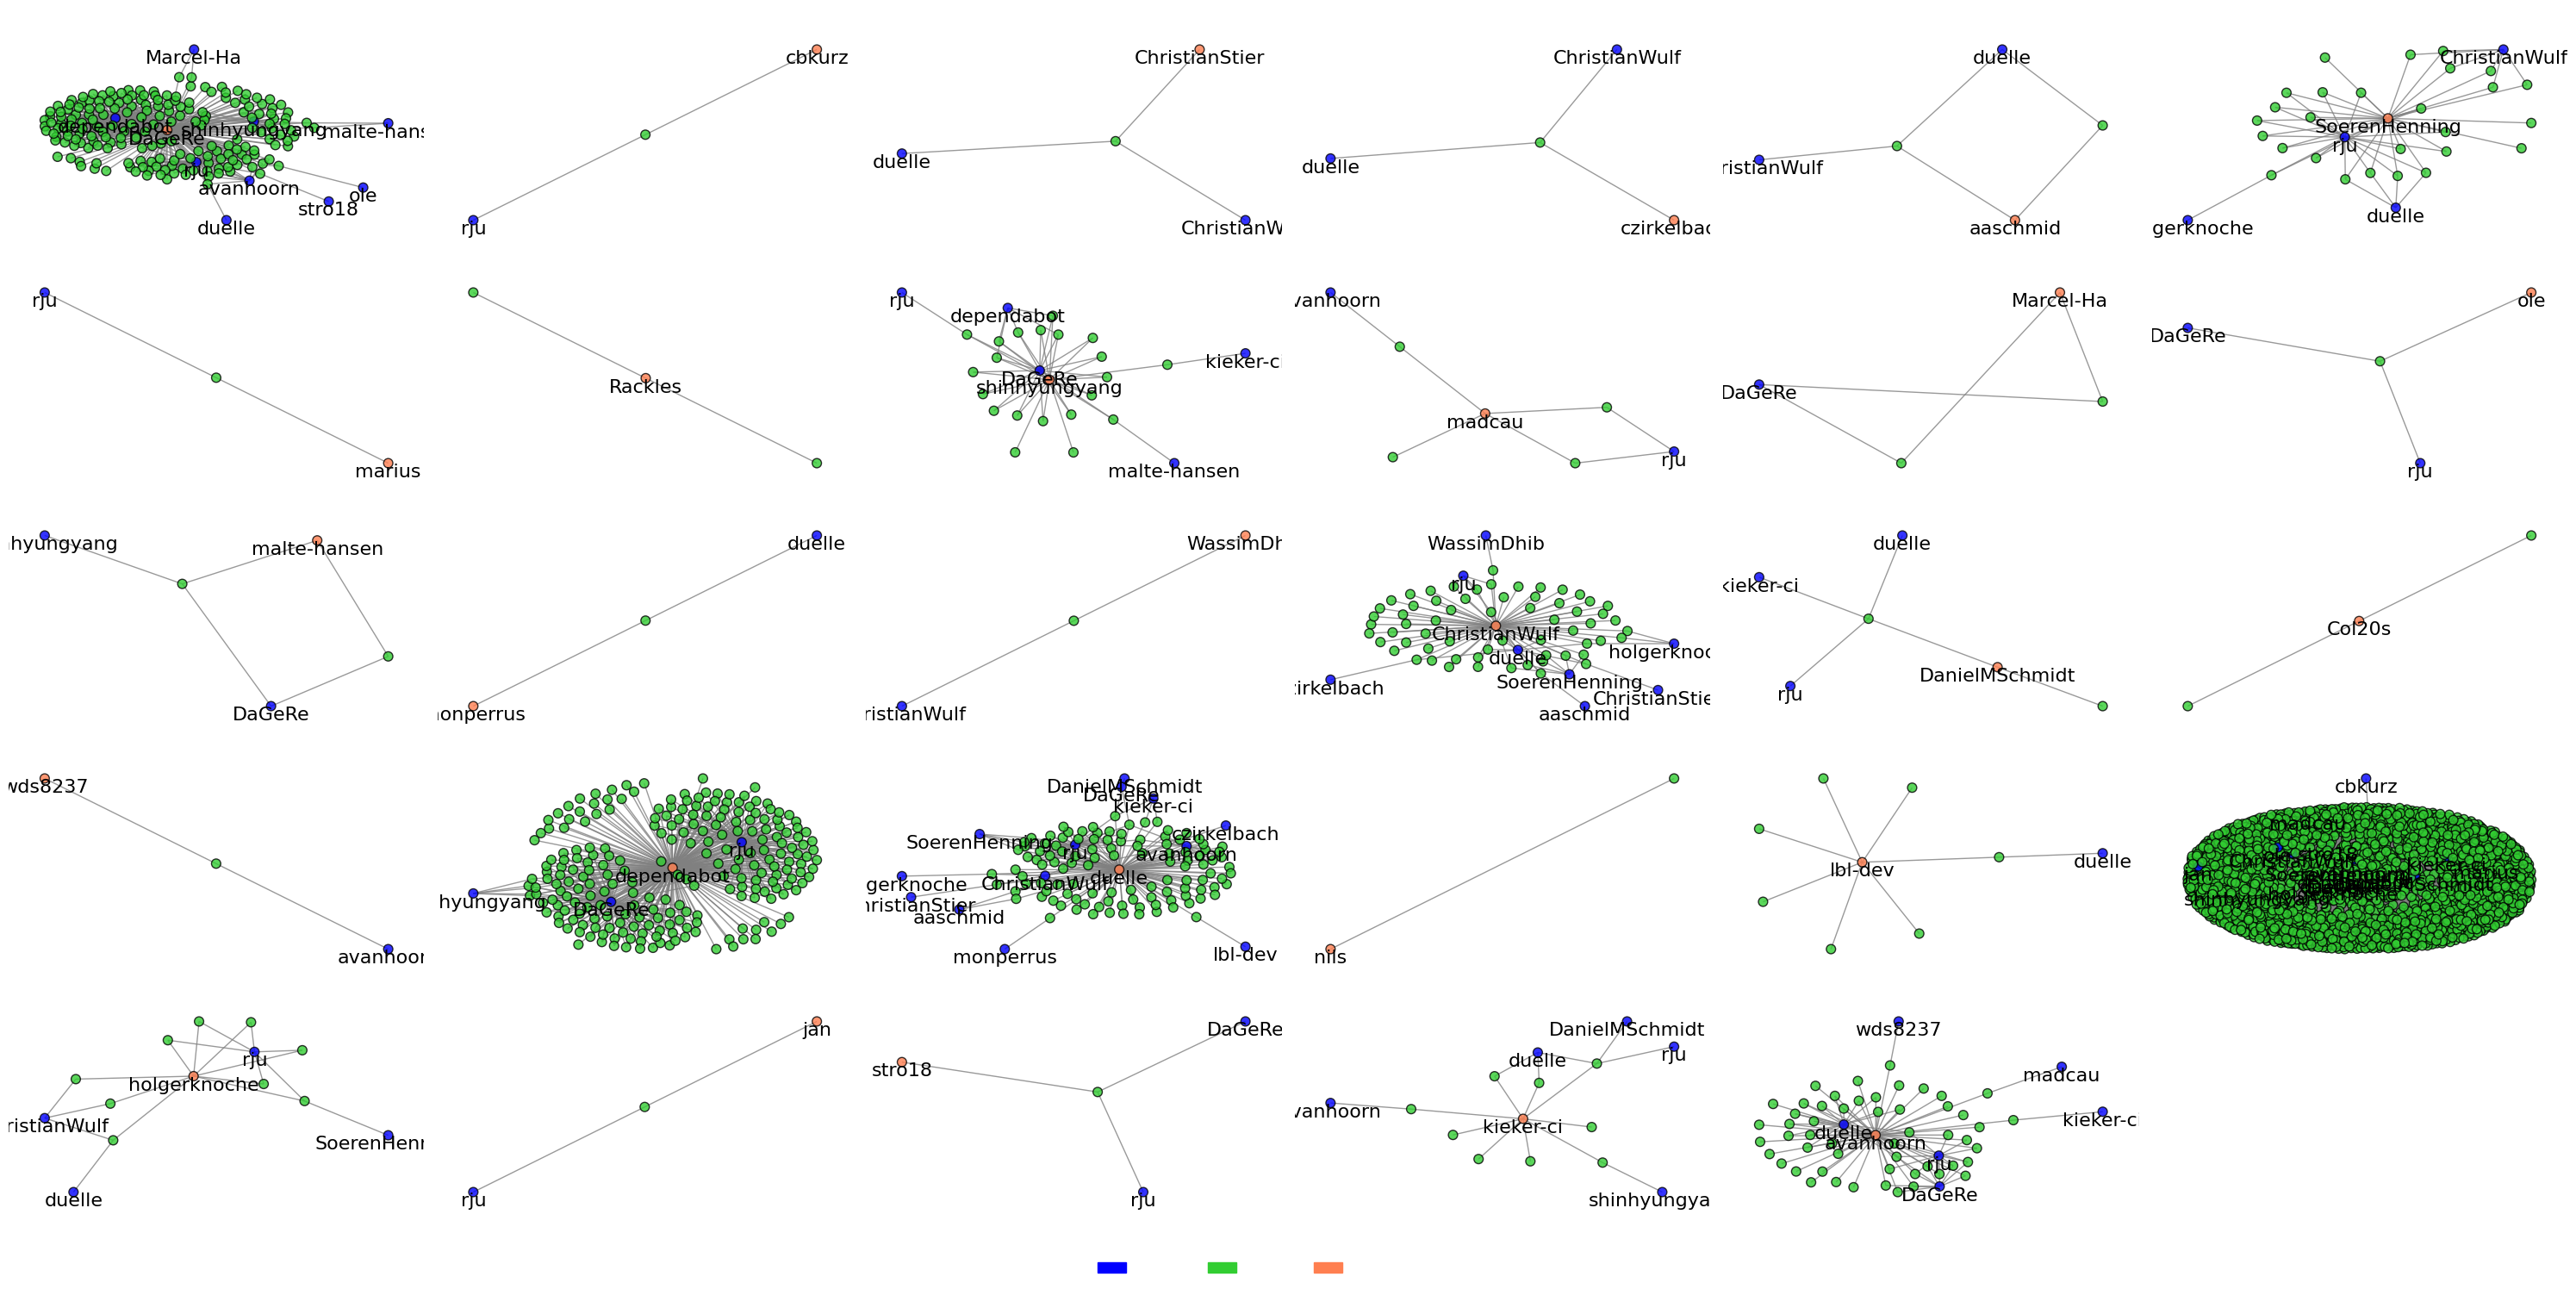

In [12]:
# Code to arrange a grid of graphs

# Number of graphs
num_graphs = len(agent_graphs)

# Determine grid size for plotting (roughly square)
cols = math.ceil(math.sqrt(num_graphs))
rows = math.ceil(num_graphs / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 3))  # Adjust size as needed

# Flatten axes array for easy iteration, if 1D
axes = axes.flatten() if num_graphs > 1 else [axes]

color_map = {
    'agent': 'blue',
    'issue': 'limegreen',
    'agent_of_interest': 'coral'
}

for ax, (agent, G) in zip(axes, agent_graphs.items()):
    pos = nx.spring_layout(G)  # Layout for nodes

    # Create list of colors based on node type
    node_colors = [color_map.get(G.nodes[node].get('type', ''), 'black') for node in G.nodes]

    agent_labels = {
        node: node.split('/')[-1]
        for node in G.nodes
        if G.nodes[node].get('type') in ['agent', 'agent_of_interest']
    }

    # Manually shift label positions down to stop them covering the nodes
    label_pos = {node: (x, y - 0.016) for node, (x, y) in pos.items() if node in agent_labels}

    nx.draw(G, pos, ax=ax, with_labels=False, node_size=60, edge_color='gray', font_size=14, node_color=node_colors,
            edgecolors='black', linewidths=1, alpha=0.8)
    nx.draw_networkx_labels(G, pos, labels=agent_labels, font_size=16, ax=ax, verticalalignment='top')

    ax.set_title(f"GitHub name: {agent.split('/')[-1]}", fontsize=18)
    ax.axis('off')

# Hide any unused subplots if graphs < rows*cols
for i in range(len(agent_graphs), len(axes)):
    axes[i].axis('off')

# Create legend patches once
legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]

# Add a single legend for the whole figure (not individual axes)
fig.legend(handles=legend_patches, loc='lower center', ncol=len(color_map), fontsize='large', frameon=False)

plt.tight_layout(rect=[0, 0.05, 1, 1])  # Leave space at bottom for legend
plt.savefig("all_agent_graphs.png", dpi=300)
print("Saved to all_agent_graphs.png")
plt.show()

## Section 2: Graph Metrics

In [13]:
# Query the database and set up a directed acyclic graph using the prov:wasAttributed and prov:wasAssociatedWith relations

# Parse results to extract agent-entity and agent-activity relationships
entities_by_agent = defaultdict(set)
activity_participants = defaultdict(set)
entities = set()
activities = set()
agents = set()

query_attributed = """
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX github2prov: <http://purl.org/github2prov/>

SELECT DISTINCT ?entity ?agent WHERE {

      ?entity prov:wasAttributedTo ?agent .
      ?entity a ?t . 
      FILTER(?t IN (github2prov:issue, github2prov:pull))
  }
"""

results = runQuery(query_attributed)
bindings = results['results']['bindings']

for b in bindings:
    entity = b['entity']['value']
    agent = b['agent']['value']

    if not entity.startswith("https://github.com/"):
        continue

    entities_by_agent[agent].add(entity)
    agents.add(agent)
    entities.add(entity)

query_associated = """
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX github2prov: <http://purl.org/github2prov/>

SELECT DISTINCT ?activity ?agent WHERE  {
    ?activity prov:wasAssociatedWith ?agent.
    ?activity a ?t
    FILTER STRSTARTS(STR(?t), STR(github2prov:))
  }
"""

results = runQuery(query_associated)
bindings = results['results']['bindings']

for b in bindings:
    activity = b['activity']['value']
    agent = b['agent']['value']

    if not entity.startswith("https://github.com/"):
        continue

    activity_participants[agent].add(activity)
    agents.add(agent)
    activities.add(activity)

# Create undirected graph of agent collaboration based on shared entities
G = nx.Graph()

# Add agent nodes
for agent in agents:
    G.add_node(agent, type='agent')

# Add entity nodes
for entity in entities:
    G.add_node(entity, type='entity')

# Add activity nodes
for activity in activities:
    G.add_node(activity, type='activity')

# Add edges between agent entity (wasAttributedTo)
for agent, ents in entities_by_agent.items():
    for ent in ents:
        G.add_edge(agent, ent, relation='wasAttributedTo')

# Add edges between agent activity (wasAssociatedWith)
for agent, acts in activity_participants.items():
    for act in acts:
        G.add_edge(agent, act, relation='wasAssociatedWith')

In [14]:
# Draw the interconnection graph for all users and write to a file
if G.number_of_nodes() == 0:
    print("No nodes to display. Check if the SPARQL query returned any agents/entities.")
else:
    print(f"Graph has {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")

    # Map node types to colors
    color_map = {
        'agent': 'skyblue',
        'entity': 'lightgreen',
        'activity': 'orange'
    }

    # Create list of colors based on node type
    node_colors = [color_map.get(G.nodes[node].get('type', ''), 'black') for node in G.nodes]

    # Optional: relabel nodes (especially if they are URIs)
    labels = {node: node.split('/')[-1] for node in G.nodes()}
    edge_weights = nx.get_edge_attributes(G, 'weight')

    # Plot and save
    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, with_labels=False, node_size=30, edge_color='gray', node_color=node_colors, edgecolors='black',
            linewidths=1, alpha=0.5)
    plt.title("Filtered Interconnectedness Graph")

    # Create legend patches
    legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
    plt.legend(handles=legend_patches, loc='best', fontsize='small', frameon=False)

    plt.savefig("interconnectedness.png", dpi=300)
    plt.close()
    print("Saved to interconnectedness.png")

Graph has 23030 nodes and 23036 edges.
Saved to interconnectedness.png


In [15]:
# Output a graph but only consider the wasAttributedTo relation

# Add entity nodes
for entity in entities:
    G.add_node(entity, type='entity')

# Add edges between agent entity (wasAttributedTo)
for agent, ents in entities_by_agent.items():
    G.add_node(agent, type='agent')
    for ent in ents:
        G.add_edge(agent, ent, relation='wasAttributedTo')

# Draw the interconnection graph for all users
if G.number_of_nodes() == 0:
    print("No nodes to display. Check if the SPARQL query returned any agents/entities.")
else:
    print(f"Graph has {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")

    # Map node types to colors
    color_map = {
        'agent': 'skyblue',
        'entity': 'lightgreen',
        'activity': 'orange'
    }

    # Create list of colors based on node type
    node_colors = [color_map.get(G.nodes[node].get('type', ''), 'black') for node in G.nodes]

    # Optional: relabel nodes (especially if they are URIs)
    labels = {node: node.split('/')[-1] for node in G.nodes()}
    edge_weights = nx.get_edge_attributes(G, 'weight')

    # Plot and save
    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, with_labels=False, node_size=30, edge_color='gray', node_color=node_colors, edgecolors='black',
            linewidths=1, alpha=0.5)
    plt.title("Filtered Interconnectedness Graph")

    # Create legend patches
    legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
    plt.legend(handles=legend_patches, loc='best', fontsize='small', frameon=False)

    plt.savefig("interconnectedness-attributed.png", dpi=300)
    plt.close()
    print("Saved to interconnectedness-attributed.png")

Graph has 23030 nodes and 23036 edges.
Saved to interconnectedness-attributed.png


In [16]:
# Output a graph but only consider wasAssociatedWith relation

G = nx.Graph()

a = []

# Add activity nodes
for activity in activities:
    G.add_node(activity, type='activity')

# Add edges between agent activity (wasAssociatedWith)
for agent, acts in activity_participants.items():
    a.append(agent)
    for act in acts:
        G.add_edge(agent, act, relation='wasAssociatedWith')

# Draw the interconnection graph for all users
if G.number_of_nodes() == 0:
    print("No nodes to display. Check if the SPARQL query returned any agents/entities.")
else:
    print(f"Graph has {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")

    # Map node types to colors
    color_map = {
        'agent': 'skyblue',
        'entity': 'lightgreen',
        'activity': 'orange'
    }

    # Create list of colors based on node type
    node_colors = [color_map.get(G.nodes[node].get('type', ''), 'black') for node in G.nodes]

    # Optional: relabel nodes (especially if they are URIs)
    labels = {node: node.split('/')[-1] for node in G.nodes()}
    edge_weights = nx.get_edge_attributes(G, 'weight')

    # Plot and save
    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, with_labels=False, node_size=30, edge_color='gray', node_color=node_colors, edgecolors='black',
            linewidths=1, alpha=0.5)
    plt.title("Filtered Interconnectedness Graph")

    # Create legend patches
    legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
    plt.legend(handles=legend_patches, loc='best', fontsize='small', frameon=False)

    plt.savefig("interconnectedness-associated.png", dpi=300)
    plt.close()
    print("Saved to interconnectedness-associated.png")

Graph has 20128 nodes and 20134 edges.
Saved to interconnectedness-associated.png


Image(value=b'GIF89a\x80\x02\xe0\x01\x87\x00\x00\xff\xff\xff\xfe\xfe\xfe\xfd\xfd\xfd\xfc\xfc\xfc\xfc\xfb\xfc\x…

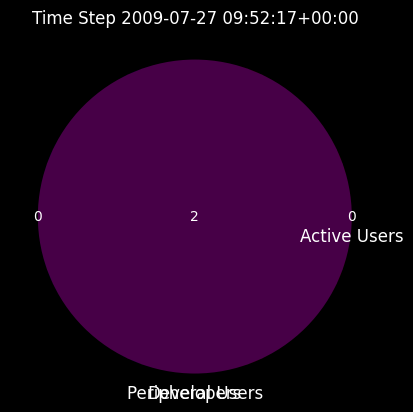

In [17]:

import dateutil.parser
import datetime
import warnings

warnings.filterwarnings(
    "ignore",
    message="Circle .* has zero area.",
    module="matplotlib_venn.layout.venn3.pairwise"
)


def active_range():
    range_activity_query = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX github2prov: <http://purl.org/github2prov/>

SELECT (max(?d) as ?maxdate) (min(?d) as ?mindate)
WHERE {

    ?activity prov:wasAssociatedWith ?agent.
    ?activity a ?t
    FILTER STRSTARTS(STR(?t), STR(github2prov:))
    ?activity prov:startedAtTime ?d.

}
    """

    results = runQuery(range_activity_query)

    first_date = None
    last_date = None
    try:
        for result in results["results"]["bindings"]:
            # print(result)
            first_date = dateutil.parser.parse(result['mindate']['value'])
            last_date = dateutil.parser.parse(result['maxdate']['value'])
        return first_date, last_date
    except KeyError:
        pass
        return None, None


def project_timeranges():
    timeranges = []
    first_date, last_date = active_range()
    return time_ranges(first_date, last_date, weeks=4)


def time_ranges(first_date, last_date, weeks=4):
    step = datetime.timedelta(weeks=weeks)
    start = first_date
    end = start + step
    while (start < last_date):
        yield (start, end)
        start = end
        end = start + step


def active(start, end):
    # calcuate interactions

    interaction_dates_query = """
    PREFIX prov: <http://www.w3.org/ns/prov#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    PREFIX github2prov: <http://purl.org/github2prov/>

    SELECT ?u ?d
    WHERE {

        ?activity prov:wasAssociatedWith ?u.
        ?activity a ?t.
        FILTER STRSTARTS(STR(?t), STR(github2prov:))
        ?activity prov:startedAtTime ?d.
        FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)

    }
    """ % (start.isoformat(), end.isoformat())

    results = runQuery(interaction_dates_query)

    agents = {}

    for result in results["results"]["bindings"]:
        # print(result)
        agent_uri = result["u"]["value"]
        date_ = result['d']['value']
        if agent_uri not in agents:
            agents[agent_uri] = [date_]
        else:
            agents[agent_uri].append(date_)

    agent_diff = {}
    for i in agents:
        dates = []
        for j in agents[i]:
            get_date_obj = dateutil.parser.parse(j)
            dates.append(get_date_obj)

        dates.sort()

        # calculate differences between pairs of dates
        differences = [(d[1] - d[0]).days for d in zip(dates, dates[1:])]
        agent_diff[i] = differences

    #print agent_diff

    p_developer = []
    a_developer = []

    today = datetime.datetime.now(datetime.timezone.utc)

    for i in agent_diff:
        last_date = dateutil.parser.parse(agents[i][-1])
        last_date = last_date.replace(tzinfo=datetime.timezone.utc)

        try:
            a = today - last_date
        except:
            print(today, last_date)

        diff = a.days

        if sum(agent_diff[i]) == 0:
            p_developer.append(i)
        elif sum(agent_diff[i]) > 10 and diff < 180:
            a_developer.append(i)
        elif sum(e > 2 for e in agent_diff[i]) > 5:
            a_developer.append(i)
        else:
            p_developer.append(i)

    return p_developer, a_developer


def closing_developers(start, end):
    closed_query = """
        PREFIX prov: <http://www.w3.org/ns/prov#>
        PREFIX github2prov: <http://purl.org/github2prov/>
        PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
        PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>

        SELECT DISTINCT ?agent
        WHERE {

                ?activity rdf:type github2prov:closed.
                ?activity prov:wasAssociatedWith ?agent.
                ?activity prov:startedAtTime ?d.

                FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)

    }
    """ % (start.isoformat(), end.isoformat())

    results = runQuery(closed_query)

    agents = []

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        agents.append(agent_uri)

    return agents


def commiting_developers(start, end):
    commit_query = """
        PREFIX prov: <http://www.w3.org/ns/prov#>
        PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
        PREFIX github2prov: <http://purl.org/github2prov/>
        PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

        SELECT DISTINCT ?agent

        WHERE {

                ?activity rdf:type github2prov:commit.
                ?activity prov:wasAssociatedWith ?agent.
                ?activity prov:startedAtTime ?d.
                FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)

    }
    """ % (start.isoformat(), end.isoformat())

    results = runQuery(commit_query)

    agents = []

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        agents.append(agent_uri)

    return agents


times = project_timeranges()
data = []
start = None
for (s, e) in times:
    if not start:
        start = s
    p_developer, a_developer = active(start, e, )
    commiters = commiting_developers(start, e)
    closers = closing_developers(start, e)
    developers = set(commiters + closers)
    if (len(p_developer) + len(a_developer) + len(developers)) > 0:
        diag = dict(date=e, p=set(p_developer), a=set(a_developer), d=set(developers))
        data.append(diag)

import matplotlib.pyplot as plt
from matplotlib_venn import venn3
from matplotlib.animation import FuncAnimation, PillowWriter

fig, ax = plt.subplots()  #add


def update(frame):
    ax.clear()
    step = data[frame]
    ax.set_title(f"Time Step {step['date']}")
    v = venn3([step['p'], step['a'], step['d']], ax=ax,
              set_labels=("Peripheral Users", "Active Users", "Developers"))


ani = FuncAnimation(fig, update, frames=len(data), interval=1000, repeat=False)

# Save the animation to a GIF
ani.save("developer_activity.gif", writer=PillowWriter(fps=10))

# Display the GIF in the notebook
i = Image(filename="developer_activity.gif")

import ipywidgets as widgets
from IPython.display import display

display(widgets.Image(value=open("developer_activity.gif", "rb").read(), format="gif"))

In [36]:
if False:
    query = """PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
    PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
    PREFIX prov: <http://www.w3.org/ns/prov#>
    PREFIX github2prov: <http://purl.org/github2prov/>
    
    SELECT ?user 
           (COUNT(DISTINCT ?commit) AS ?Commits)
           (COUNT(DISTINCT ?pr) AS ?PRs)
           (COUNT(DISTINCT ?issue) AS ?Issues)
           (COUNT(DISTINCT ?comment) AS ?Comments)
           (COUNT(DISTINCT ?star) AS ?Stars)
           (COUNT(DISTINCT ?fork) AS ?Forks)
    WHERE {
       {
        ?user a prov:Agent .
    
        OPTIONAL { 
            ?e prov:wasAssociatedWith ?user.
            ?e a prov:Activity.
            ?i a github2prov:issue.
            ?iv prov:specializationOf ?i.
            ?iv prov:wasGeneratedBy ?e. }
        OPTIONAL { 
            ?user a prov:Agent.
            ?activity prov:wasAttributedTo ?user.
            ?activity rdf:type ?type.
    
            FILTER (
              REGEX(STR(?activity), "/pull/")) 
            }
        OPTIONAL { 
            ?user a prov:Agent.
            ?activity prov:wasAttributedTo ?user.
            ?activity rdf:type ?type.
    
            FILTER (
              REGEX(STR(?activity), "/issue/")) 
            }
        OPTIONAL { ?comment a github2prov:comment ; prov:wasAssociatedWith ?user . }
        OPTIONAL { ?star a github2prov:star ; prov:wasAssociatedWith ?user . }
        OPTIONAL { ?fork a github2prov:fork ; prov:wasAssociatedWith ?user . }
      }
    }
    GROUP BY ?user"""

    results = runQuery(query)


    # Classification function
    def classify_user(row):
        if row['Commits'] > 0 or row['PRs'] > 0:
            return 'Developer'
        elif row['Issues'] > 0 or row['Comments'] > 0:
            return 'Active User'
        elif row['Stars'] > 0 or row['Forks'] > 0:
            return 'Peripheral User'
        else:
            return 'Unknown'


    # Parse SPARQL results into a list of dicts
    data = []
    for row in results["results"]["bindings"]:
        data.append({
            "User": row["user"]["value"],
            "Commits": int(row.get("Commits", {}).get("value", 0)),
            "PRs": int(row.get("PRs", {}).get("value", 0)),
            "Issues": int(row.get("Issues", {}).get("value", 0)),
            "Comments": int(row.get("Comments", {}).get("value", 0)),
            "Stars": int(row.get("Stars", {}).get("value", 0)),
            "Forks": int(row.get("Forks", {}).get("value", 0)),
        })

    # Create DataFrame
    df = pd.DataFrame(data)

    # Add classification column
    df['Category'] = df.apply(classify_user, axis=1)

    # Reorder columns (optional)
    df = df[['User', 'Category', 'Commits', 'PRs', 'Issues', 'Comments', 'Stars', 'Forks']]

    # Print the DataFrame as a table
    print(df.to_string(index=False))



In [37]:
 if False:
    query = """
    PREFIX prov: <http://www.w3.org/ns/prov#>
    PREFIX github2prov: <http://purl.org/github2prov/>
    PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
    
    SELECT ?month (count(?month) as ?count)
    WHERE {
     {
        ?activity rdf:type github2prov:starred.
        ?activity prov:wasAssociatedWith ?agent.
        ?activity prov:startedAtTime ?d.
        BIND (substr(str(?d), 1, 7) as ?month)
      }
    }
    GROUP BY ?month
    ORDER BY ?month
    """

    results = runQuery(query)

    data = dict()
    for result in results["results"]["bindings"]:
        m = result["month"]["value"]
        c = result["count"]["value"]
        data[m] = c

    min_key, max_key = min(data.keys()), max(data.keys())


    def key_parse(k):
        return [int(x) for x in k.split("-")]


    def make_key(y, m):
        return f"{y}-{m:02d}"


    y, m = key_parse(min_key)
    ye, me = key_parse(max_key)

    a = []
    while (y <= ye) or (m <= me):
        m = m + 1
        if m == 13:
            m = 1
            y = y + 1
        a.append(make_key(y, m))

    for x in a:
        if not x in data:
            data[x] = 0

    months = sorted(data.keys())
    counts = [int(data[k]) for k in months]

    # Plotting
    plt.figure(figsize=(10, 5))
    plt.bar(months, counts, color='skyblue')
    plt.xlabel("Month")
    plt.ylabel("Count")
    plt.title("Stars per Month")
    plt.xticks(rotation=45)
    plt.tight_layout()

## Section 4: Role analysis

Determine the role of a user based on their activity in the repository.

In [38]:
# Supporting queries

# Number of commits
commits_started = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?c) as ?count)
WHERE {


    ?c a github2prov:commit.
    ?c prov:wasAssociatedWith ?agent.
  
}
Group By ?agent
"""

# Number of commits
commits_started_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?c) as ?count)
WHERE {
{

    ?c a github2prov:commit.
    ?c prov:wasAssociatedWith ?agent.
    ?c  prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
  }
}
Group By ?agent
"""

# Number of line of code changed in the codebase

# Number of files worked on

# data in database might be wrong
# Number of pull requests (PRs) made
pullrequests_opened = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?pulls) as ?count)
WHERE {
 {
    ?pulls prov:wasAttributedTo ?agent.
    ?pulls rdf:type github2prov:pull.
 }
}
Group By ?agent
"""
pullrequests_opened_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?pulls) as ?count)
WHERE {
{
    ?pulls prov:wasAttributedTo ?agent.
    ?pulls rdf:type github2prov:pull.
    ?pulls prov:wasGeneratedBy ?e.
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
 }
}
Group By ?agent
"""

# Avg. length of PR descriptions*

# Number of issues reported
issues_opened = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?i) as ?count)
WHERE {
{
    ?i a github2prov:issue.
    ?i prov:wasAttributedTo ?agent.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull. }
}
}
Group By ?agent
"""
issues_opened_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?iy) as ?count)
WHERE {
 {
    ?i a github2prov:issue.
    ?i prov:wasAttributedTo ?agent.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull. }
    ?i prov:wasGeneratedBy ?e.
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
}
}
Group By ?agent
"""

# Avg. length of issue descriptions*

# data in database might be wrong
# Number of comments made in issue discussions

issue_comments = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e a prov:Activity.
    ?e rdf:type github2prov:comment.
    ?iv prov:wasGeneratedBy ?e.
    ?iv prov:specializationOf ?i.
    ?i a github2prov:issue.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
    ?e prov:wasAssociatedWith ?agent.
}
}
Group By ?agent
"""
issue_comments_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
{
    ?e a prov:Activity.
    ?e rdf:type github2prov:comment.
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)  }
    ?iv prov:wasGeneratedBy ?e.
    ?iv prov:specializationOf ?i.
    ?i a github2prov:issue.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
    ?e prov:wasAssociatedWith ?agent.
}
Group By ?agent
"""

# Avg. length of issue comments*

# data in database might be wrong
# Number of comments made in PR discussions
pullrequest_comments = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
{
    ?e prov:wasAssociatedWith ?agent.
    ?e a prov:Activity.
    ?e rdf:type github2prov:comment.
    ?i a github2prov:pull.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
  }
}
Group By ?agent
"""
pullrequest_comments_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e prov:wasAssociatedWith ?agent.
    ?e a prov:Activity.
    ?e rdf:type github2prov:comment.
    ?i a github2prov:pull.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
    }
}
Group By ?agent
"""

# Avg. length of PR comments*

# data in database might be wrong
# Number of times being mentioned in issue comments

mention_issue_comments = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
{
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:mentioned.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
  }
}
Group By ?agent
"""
mention_issue_comments_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
{
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:mentioned.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
    }
}
Group By ?agent
"""

# data in database might be wrong
# Number of times being mentioned in PR comments
mention_pull_comments = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
  {
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:mentioned.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?i rdf:type github2prov:pull.
  }
}
Group By ?agent
"""
mention_pull_comments_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:mentioned.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?i rdf:type github2prov:pull.
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
  }
}
Group By ?agent
"""

# data in database might be wrong
# Number of times referred other issues/PRs in issue comments
referred_issue_comments = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:referenced.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
  FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
  }
}
Group By ?agent
"""
referred_issue_comments_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:referenced.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
  }
}
Group By ?agent
"""

# data in database might be wrong
# Number of times referred other issues/PRs in PR comments
referred_pull_comments = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:referenced.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?i rdf:type github2prov:pull.
  }
}
Group By ?agent
"""
referred_pull_comments_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?e prov:wasAssociatedWith ?agent.
    ?e rdf:type github2prov:referenced.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?i rdf:type github2prov:pull.
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
  }
}
Group By ?agent
"""

# data in database might be wrong
# Number of times applied or removed labels on issues
labels_issue = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    
    ?e prov:wasAssociatedWith ?agent.
    {?e rdf:type github2prov:labeled.}
    UNION
    {?e rdf:type github2prov:unlabeled.}
    FILTER NOT EXISTS {?i rdf:type github2prov:pull.}
 }
}
Group By ?agent
"""
labels_issue_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    
    ?e prov:wasAssociatedWith ?agent.
    {?e rdf:type github2prov:labeled.}
    UNION
    {?e rdf:type github2prov:unlabeled.}
    FILTER NOT EXISTS {?i rdf:type github2prov:pull.}
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
 }
}
Group By ?agent
"""

# data in database might be wrong
# Number of times applied or removed labels on PRs
labels_pull = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?i rdf:type github2prov:pull.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    
    ?e prov:wasAssociatedWith ?agent.
    {?e rdf:type github2prov:labeled.}
    UNION
    {?e rdf:type github2prov:unlabeled.}
 }
}
Group By ?agent
"""
labels_pull_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?agent (count(distinct ?e) as ?count)
WHERE {
 {
    ?i rdf:type github2prov:pull.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    
    ?e prov:wasAssociatedWith ?agent.
    {?e rdf:type github2prov:labeled.}
    UNION
    {?e rdf:type github2prov:unlabeled.}
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
 }
}
Group By ?agent
"""

# Number of times closed issues
closed_issue = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?agent (count(distinct ?i) as ?count)
 WHERE {
  {
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?e rdf:type github2prov:closed.
    ?e prov:wasAssociatedWith ?agent.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
  }
}
GROUP BY ?agent
"""
closed_issue_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?agent (count(distinct ?i) as ?count)
 WHERE {
  {
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?e rdf:type github2prov:closed.
    ?e prov:wasAssociatedWith ?agent.
    FILTER NOT EXISTS { ?i rdf:type github2prov:pull.}
    ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
  }
}
GROUP BY ?agent
"""

# data in database might be wrong
# Number of times closed pull requests
closed_pull = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX or: <http://openresearch.org/vocab/>
PREFIX pr: <http://purl.org/ontology/prv/core#>
PREFIX pro: <http://purl.org/hpi/patchr#>
PREFIX aprov: <http://purl.org/a-proc#>
PREFIX type: <http://info.deepcarbon.net/schema/type#>

SELECT ?agent (count(distinct ?activity) as ?count)
WHERE {
{
    ?i a github2prov:pull.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?e rdf:type github2prov:pull.
    ?e prov:wasAssociatedWith ?agent.
    ?activity prov:wasAssociatedWith ?agent.
    ?activity rdf:type github2prov:closed.  
 }
}
Group By ?agent
"""
closed_pull_time = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX or: <http://openresearch.org/vocab/>
PREFIX pr: <http://purl.org/ontology/prv/core#>
PREFIX pro: <http://purl.org/hpi/patchr#>
PREFIX aprov: <http://purl.org/a-proc#>
PREFIX type: <http://info.deepcarbon.net/schema/type#>

SELECT ?agent (count(distinct ?activity) as ?count)
WHERE {
 {
    ?i a github2prov:pull.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?e.
    ?e rdf:type github2prov:pull.
    ?e prov:wasAssociatedWith ?agent.
    ?activity prov:wasAssociatedWith ?agent.
    ?activity rdf:type github2prov:closed.  
        ?e prov:startedAtTime ?d.
    FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
 }
}
Group By ?agent
"""

In [39]:
sparql = kieker_client


def active(start, end):
    # calcuate interactions

    interaction_dates_query = """
    PREFIX prov: <http://www.w3.org/ns/prov#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    PREFIX github2prov: <http://purl.org/github2prov/>
    PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
    PREFIX or: <http://openresearch.org/vocab/>
    PREFIX pr: <http://purl.org/ontology/prv/core#>
    PREFIX pro: <http://purl.org/hpi/patchr#>
    PREFIX aprov: <http://purl.org/a-proc#>
    PREFIX type: <http://info.deepcarbon.net/schema/type#>

    SELECT ?u ?d
    WHERE {
     {
        ?a prov:startedAtTime ?d.
        ?a prov:wasAssociatedWith ?u.
        FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
        ?a a ?t.
        FILTER STRSTARTS(STR(?t), STR(github2prov:))
     }
    }
    """ % (start.isoformat(), end.isoformat())

    sparql.setQuery(interaction_dates_query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = {}

    for result in results["results"]["bindings"]:
        agent_uri = result["u"]["value"]
        date_ = result['d']['value']
        if agent_uri not in agents:
            agents[agent_uri] = [date_]
        else:
            agents[agent_uri].append(date_)

    return agents.keys()


def results(body, title):
    q = body
    sparql.setQuery(q)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    all = {}

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        count = int(result["count"]["value"])
        all[agent_uri] = count
    return title, all


def results_time(body, title, start, end):
    q = body % (start.isoformat(), end.isoformat())
    sparql.setQuery(q)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    all = {}

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        count = int(result["count"]["value"])
        all[agent_uri] = count
    return title, all


def build_weights():
    weights_raw = [
        ["Metrics", "# of commits made", "# of line of code changed in the codebase", "# of files worked on",
         "# of pull requests (PRs) made", "Avg. length of PR descriptions", "# of issues reported",
         "Avg. length of issue descriptions", "# of comments made in issue discussions",
         "Avg. length of issue comments", "# of comments made in PR discussions", "Avg.  length of PR comments",
         "# of times being mentioned in issue comments", "# of times being mentioned in PR comments",
         "# of times referred other issues/PRS in issue comments",
         "# of times referred other issues/PRS in PR comments", "# of times applied or removed labels on issues",
         "# of times applied or removed labels on PRS", "# of times closed issues", "# of times closed pull requests",
         "Activity Name"],
        ["Factor1", 0.00, 0.00, 0.00, 0.06, 0.05, 0.30, -0.01, 0.52, -0.02, 0.72, 0.00, 0.78, 1.02, -0.12, 0.06, 0.06,
         0.58, 0.28, -0.30, "Knowledge. Sharing"],
        ["Factor2", 1.03, 1.03, 0.26, -0.04, -0.01, 0.04, 0.00, -0.01, 0.01, -0.01, -0.01, 0.01, 0.01, 0.02, 0.00, 0.01,
         0.00, -0.03, -0.08, "Code Contrib"],
        ["Factor3", 0.02, 0.02, -0.07, -0.11, -0.03, 0.18, -0.03, 0.30, 0.00, 0.09, 0.04, 0.1, -0.16, 1.06, 0.59, 0.72,
         0.13, 0.08, 0.07, "Issue Coord"],
        ["Factor4", -0.07, -0.07, 0.35, 0.45, -0.01, 0.11, 0.00, 0.24, -0.01, 0.03, -0.02, 0.01, -0.2, -0.07, -0.05,
         0.24, -0.03, 0.65, 0.95, "Prog.  Ctrl."],
        ["Factor5", -0.04, -0.04, 0.45, 0.70, 0.13, 0.11, 0.02, -0.13, 0.00, 0.25, 0.09, -0.02, 0.2, 0.02, 0.21, -0.23,
         0.15, -0.24, 0.33, "Code Twking."],
        ["Factor6", 0.05, 0.05, -0.17, 0.05, 0.01, 0.35, 0.16, 0.16, 0.1, -0.12, 0.03, 0.14, -0.22, -0.15, 0.00, -0.07,
         -0.07, 0.04, -0.06, "Issue Rptg."],
        ["h2", 0.997, 0.997, 0.575, 0.876, 0.022, 0.643, 0.024, 0.900, 0.008, 0.820, 0.013, 0.840, 0.743, 0.808, 0.503,
         0.725, 0.516, 0.701, 0.857, ""],
        ["u2", 0.003, 0.003, 0.425, 0.124, 0.978, 0.358, 0.976, 0.100, 0.992, 0.180, 0.987, 0.160, 0.257, 0.192, 0.497,
         0.275, 0.485, 0.299, 0.144, ""]
    ]

    transpose = list(zip(*weights_raw))
    rows = [x[0] for x in transpose]
    columns = transpose[-1][1:7] + transpose[0][-2:]
    weights_data = [x[1:] for x in transpose[1:-1]]
    return pd.DataFrame(weights_data, columns=columns, index=[x[0] for x in transpose][1:-1])


weights = build_weights()

mapping = {}
mapping['closed_issue'] = '# of times closed issues'
mapping['closed_pull'] = '# of times closed pull requests'
mapping['commits_started'] = '# of commits made'
mapping['issue_comments'] = '# of comments made in issue discussions'
mapping['issues_opened'] = '# of issues reported'
mapping['labels_issue'] = '# of times applied or removed labels on issues'
mapping['labels_pull'] = '# of times applied or removed labels on PRS'
mapping['mention_issue_comments'] = '# of times being mentioned in issue comments'
mapping['mention_pull_comments'] = '# of times being mentioned in PR comments'
mapping['pullrequest_comments'] = '# of comments made in PR discussions'
mapping['pullrequests_opened'] = '# of pull requests (PRs) made'
mapping['referred_issue_comments'] = '# of times referred other issues/PRS in issue comments'
mapping['referred_pull_comments'] = '# of times referred other issues/PRS in PR comments'

query_strings = dict(
    commits_started=commits_started,
    pullrequests_opened=pullrequests_opened,
    issues_opened=issues_opened,
    issue_comments=issue_comments,
    pullrequest_comments=pullrequest_comments,
    mention_issue_comments=mention_issue_comments,
    mention_pull_comments=mention_pull_comments,
    referred_issue_comments=referred_issue_comments,
    referred_pull_comments=referred_pull_comments,
    labels_issue=labels_issue,
    labels_pull=labels_pull,
    closed_issue=closed_issue,
    closed_pull=closed_pull
)
query_strings_time = dict(
    commits_started=commits_started_time,
    pullrequests_opened=pullrequests_opened_time,
    issues_opened=issues_opened_time,
    issue_comments=issue_comments_time,
    pullrequest_comments=pullrequest_comments_time,
    mention_issue_comments=mention_issue_comments_time,
    mention_pull_comments=mention_pull_comments_time,
    referred_issue_comments=referred_issue_comments_time,
    referred_pull_comments=referred_pull_comments_time,
    labels_issue=labels_issue_time,
    labels_pull=labels_pull_time,
    closed_issue=closed_issue_time,
    closed_pull=closed_pull_time
)


def metrics_all():
    r = {}
    for i, query in query_strings.items():
        t = results(query, i)
        r[i] = t[1]
    return r


def metrics_timed():
    by_times = []
    for (start, end) in project_timeranges():
        tr = {}
        for i, query in query_strings_time.items():
            t = results_time(query, i, start, end)
            tr[i] = t[1]
        by_times.append(dict(start=start, end=end, r=tr))
    return by_times


def make_timed_data(by_times):
    u_set = set()
    short_users = []
    c_set = set()
    for t in by_times:
        for analysis in t['r'].values():
            for u in analysis.keys():
                u_set.add(u)
        for c in t['r'].keys():
            c_set.add(c)
    columns = sorted(c_set)
    users = sorted(u_set)
    dates = [str(x['start']) for x in by_times]

    dd = OrderedDict()
    for c in columns:
        col_data = []
        for u in users:
            for t in by_times:
                col_data.append(t['r'][c].get(u, 0))
        dd[c] = col_data

    midx = pd.MultiIndex.from_product([users, dates], names=('users', 'dates'))
    return pd.DataFrame(dd, index=midx)


def metrics_for_month(timed_data, month):
    len(timed_data.index.levels[1])
    times = timed_data.index.levels[1]
    return timed_data.loc[pd.IndexSlice[:, times[0:month + 1]], :].groupby(level="users").sum()


def factors_for_month(by_times, month):
    timed_data = make_timed_data(by_times)
    user_activity = metrics_for_month(timed_data, month)
    normalized = user_activity / user_activity.sum()
    normalized.fillna(0, inplace=True)

    selected_weights = weights.loc[[mapping[x] for x in normalized.columns]]
    selected_weights.index = normalized.columns
    factors = normalized.dot(selected_weights).drop('h2', axis=1).drop('u2', axis=1)
    factors -= factors.min()
    factors = factors.reindex(factors.sum(axis=1).sort_values(ascending=False).index)

    return factors

In [51]:
# Calculate metrics
r = metrics_all()

In [41]:
by_times = metrics_timed()

In [53]:
users = set()
for analysis in r.values():
    for u in analysis.keys():
        users.add(u)

n_users = len(users)

columns = sorted(r.keys())
data = []
short_users = []
for u in users:
    d = [r[x].get(u, 0) for x in columns]
    data.append(d)
    un = u.replace("https://api.github.com/users/", "")
    short_users.append(un)

user_activity = pd.DataFrame(data, columns=columns, index=short_users)

In [43]:
users


{'https://github.com/ChristianStier',
 'https://github.com/ChristianWulf',
 'https://github.com/Col20s',
 'https://github.com/DaGeRe',
 'https://github.com/DanielMSchmidt',
 'https://github.com/JanWaller',
 'https://github.com/Marcel-Ha',
 'https://github.com/Rackles',
 'https://github.com/RvonMassow',
 'https://github.com/ShaggsOn',
 'https://github.com/SoerenHenning',
 'https://github.com/WassimDhib',
 'https://github.com/aaschmid',
 'https://github.com/apps/dependabot',
 'https://github.com/avanhoorn',
 'https://github.com/cbkurz',
 'https://github.com/czirkelbach',
 'https://github.com/danishmanzoor',
 'https://github.com/dependabot%5Bbot%5D',
 'https://github.com/duelle',
 'https://github.com/holgerknoche',
 'https://github.com/iaavo',
 'https://github.com/jan',
 'https://github.com/kieker-ci',
 'https://github.com/lbl-dev',
 'https://github.com/madcau',
 'https://github.com/malte-hansen',
 'https://github.com/marius',
 'https://github.com/monperrus',
 'https://github.com/nexxTM',

### Activity Metrics

The following table shows statistics about the activities performed in the project, these activities are identitied by J.Cheng and J.L.C Guo[1] and are used to automatically classify the role played in a project by GitHub users.

In [44]:
# Ignore some users/agents that skew the figures
try:
    user_activity = user_activity.drop("https://github.com/rju")
    user_activity = user_activity.drop("https://github.com/apps/dependabot")
except:
    pass
user_activity

,closed_issue,closed_pull,commits_started,issue_comments,issues_opened,labels_issue,labels_pull,mention_issue_comments,mention_pull_comments,pullrequest_comments,pullrequests_opened,referred_issue_comments,referred_pull_comments
https://github.com/DaGeRe,1,0,550,2,8,0,0,0,0,50,97,0,0
https://github.com/cbkurz,0,0,1,0,0,0,0,0,0,1,1,0,0
https://github.com/iaavo,0,0,2,0,0,0,0,0,0,0,1,0,0
https://github.com/ChristianStier,0,0,0,0,0,0,0,0,0,2,0,0,0
https://github.com/czirkelbach,0,0,0,0,0,0,0,0,0,0,1,0,0
https://github.com/aaschmid,0,0,1,0,0,0,0,0,0,5,2,0,0
https://github.com/ShaggsOn,0,0,11,0,0,0,0,0,0,0,0,0,0
https://github.com/danishmanzoor,0,0,0,0,0,0,0,0,0,0,1,0,0
https://github.com/SoerenHenning,0,0,484,0,0,0,0,0,0,5,9,0,1
https://github.com/teeratpitakrat,0,0,98,0,0,0,0,0,0,0,0,0,0


In [45]:
normalized = user_activity / user_activity.sum()
normalized.fillna(0, inplace=True)

In [46]:
selected_weights = weights.loc[[mapping[x] for x in normalized.columns]]
selected_weights.index = normalized.columns
factors = normalized.dot(selected_weights).drop('h2', axis=1).drop('u2', axis=1)
factors -= factors.min()
factors = factors.reindex(factors.sum(axis=1).sort_values(ascending=False).index)


## Factor Loading and Normalisation

The following table is the result of normalising the data.

In [47]:
normalized

,closed_issue,closed_pull,commits_started,issue_comments,issues_opened,labels_issue,labels_pull,mention_issue_comments,mention_pull_comments,pullrequest_comments,pullrequests_opened,referred_issue_comments,referred_pull_comments
https://github.com/DaGeRe,1.0,0.0,0.165017,0.333333,1.0,0.0,0.0,0.0,0.0,0.328947,0.323333,0.0,0.0
https://github.com/cbkurz,0.0,0.0,0.000300,0.000000,0.0,0.0,0.0,0.0,0.0,0.006579,0.003333,0.0,0.0
https://github.com/iaavo,0.0,0.0,0.000600,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.003333,0.0,0.0
https://github.com/ChristianStier,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.013158,0.000000,0.0,0.0
https://github.com/czirkelbach,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.003333,0.0,0.0
https://github.com/aaschmid,0.0,0.0,0.000300,0.000000,0.0,0.0,0.0,0.0,0.0,0.032895,0.006667,0.0,0.0
https://github.com/ShaggsOn,0.0,0.0,0.003300,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
https://github.com/danishmanzoor,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.003333,0.0,0.0
https://github.com/SoerenHenning,0.0,0.0,0.145215,0.000000,0.0,0.0,0.0,0.0,0.0,0.032895,0.030000,0.0,0.2
https://github.com/teeratpitakrat,0.0,0.0,0.029403,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0


The following table is the result of applying the factor loadings of the activity metrics described by J.Cheng and J.L.C Guo [1] to the project's data.

In [48]:
primary_activities = factors.idxmax(axis=1)
primary_activities

https://github.com/DaGeRe                 Knowledge. Sharing
https://github.com/duelle                 Knowledge. Sharing
https://github.com/shinhyungyang                 Issue Coord
https://github.com/SoerenHenning                Code Contrib
https://github.com/avanhoorn                    Code Contrib
https://github.com/JanWaller                    Code Contrib
https://github.com/ChristianWulf                Code Twking.
https://github.com/jan                           Issue Rptg.
https://github.com/marius                        Issue Rptg.
https://github.com/nils                          Issue Rptg.
https://github.com/WassimDhib                    Issue Coord
https://github.com/holgerknoche                  Issue Rptg.
https://github.com/dependabot%5Bbot%5D           Issue Rptg.
https://github.com/lbl-dev                       Issue Rptg.
https://github.com/aaschmid                      Issue Rptg.
https://github.com/teeratpitakrat                Issue Rptg.
https://github.com/kieke

## Project Roles

The following radar charts show the roles for each user.  The roles played by users are a combination of one or more of the following categories [1]:
* **Knowledge sharing** - Describes the activites commenting, being mentioned in comments, and modifying labels on PRs.
* **Code contribution** - Describes activites that contributes to the codebase.
* **Issue coordination** - Describes activites that involve referring and label manipulating actions.
* **Progress control** - Describes the activities of closing issues or PRs.
* **Code Tweaking** - Describes the activities of making PRs.
* **Issue reporting** -  Describes the activity of reporting issues.

/var/folders/_s/z3zlc1xs4hb_jvdfzgx93f8h0000gn/T/ipykernel_61645/2528573324.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  my_palette = plt.cm.get_cmap("Set2", len(factors.index))


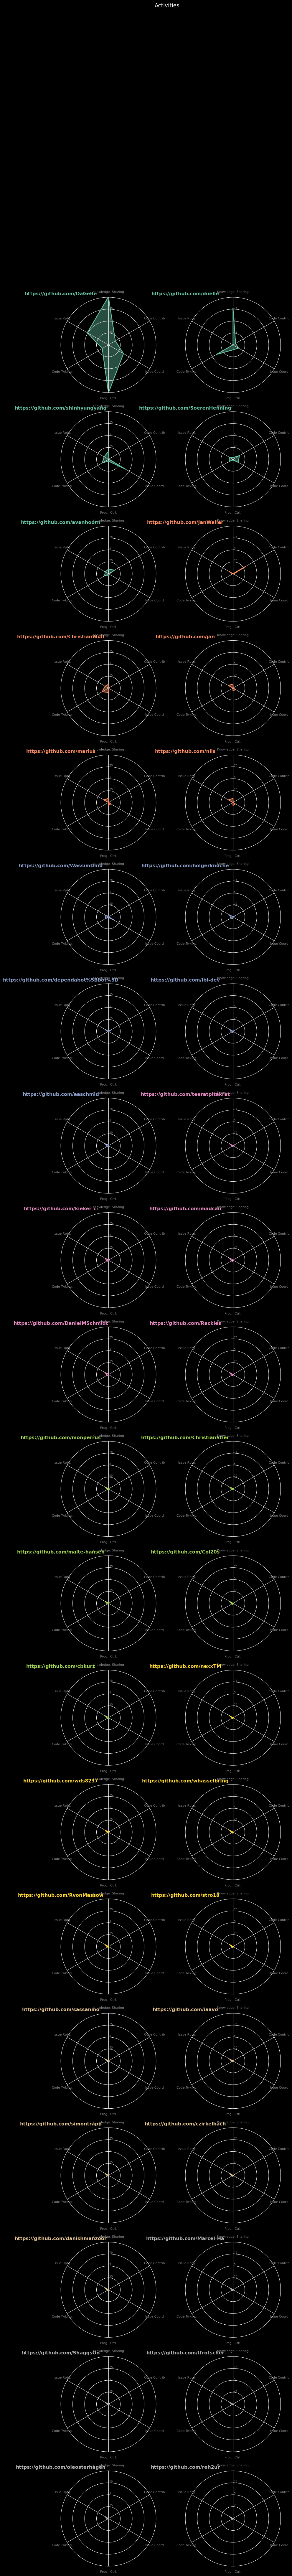

In [50]:
def make_spider(df, row, title, color):
    # number of variable
    categories = list(df)
    N = len(categories)

    # What will be the angle of each axis in the plot? (we divide the plot / number of variable)
    angles = [n / float(N) * 2 * math.pi for n in range(N)]
    angles += angles[:1]

    # Initialise the spider plot
    ax = plt.subplot(math.ceil(len(df) / 2), 2, row + 1, polar=True, )
    #plt.subplots_adjust(bottom=0.1, right=0.8, top=0.9)

    # If you want the first axis to be on top:
    ax.set_theta_offset(math.pi / 2)
    ax.set_theta_direction(-1)

    # Draw one axe per variable + add labels labels yet
    plt.xticks(angles[:-1], categories, color='grey', size=8)

    # Draw ylabels
    ax.set_rlabel_position(0)
    plt.yticks([0.25, 0.5, 0.75], [".25", ".5", ".75"], color="grey", size=7)
    plt.ylim(0, 1)

    # Ind1
    values = df.loc[df.index[row]].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, color=color, linewidth=2, linestyle='solid')
    ax.fill(angles, values, color=color, alpha=0.4)

    plt.title(title, size=12, color=color, y=1, x=0, fontweight="bold")


num = len(factors)

# initialize the figure
my_dpi = 96

plt.figure(figsize=(1000 / my_dpi, math.ceil(num / 2) * 500 / my_dpi), dpi=my_dpi)
plt.suptitle('Activities', fontsize=14)

# Create a color palette:
my_palette = plt.cm.get_cmap("Set2", len(factors.index))

for row in range(0, num):  #len(factors.index)):
    un = factors.index[row].replace("https://api.github.com/users/", "")

    make_spider(factors[0:num], row=row, title=un, color=my_palette(row))

## Ratio of Roles in the Project

The following treemap shows the ratio of users primary roles in the project.

In [ ]:
#pa = primary_activities.value_counts()

#plt.figure()
#my_palette = plt.cm.get_cmap("Set2", len(factors.index))
#colors = [my_palette(0),my_palette(1),my_palette(2), my_palette(3), my_palette(4), my_palette(5)]
#squarify.plot(sizes=pa,label=pa.index, alpha=.3, pad=2)
#plt.axis('off')
#plt.suptitle('Ratio of Users Roles', fontsize=14)
#plt.show()

class Square:
    _ax = None
    _colours = None
    _project = None

    def __init__(self, ax):
        self._ax = ax

    def clear(self):
        self._ax.clear()

    def prepare(self, project):
        if self._project != project or not self._analysis:
            self._analysis = self._prepare(project)
            self._project = project

    def plot(self, month):
        self.clear()
        self._ax.axis("off")
        f = factors_for_month(by_times, month)
        print(f)
        primary_activities = f.idxmax(axis=1)
        pa = primary_activities.value_counts()
        print(pa)
        squarify.plot(sizes=pa, label=pa.index, alpha=.3, pad=2, ax=self._ax)

    def _prepare(self, project):
        return None

In [ ]:
primary_activities.value_counts()


# Active Users

The following venn diagram shows the number of users who were active in the last 6 months, and had a role of a developer or peripheral users.

* **Developers** Users who perform commits, close issues, and pull requests
* **Peripheral Developers** Users who contribute to issue reporting, both opening and commenting.
* **Active Users** Users who were activty in the last 6 months (180 days)


In [28]:
first_commit_all_users = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?u (max(?d) as ?maxdate) (min(?d) as ?mindate) (count(distinct ?i) as ?count)
WHERE {
  {

    ?i a prov:Entity.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?a.
    ?a prov:startedAtTime ?d.
    ?a prov:wasAssociatedWith ?u
 }
    }
Group By ?u

"""

last_commit_all_users = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>


SELECT ?u (max(?d) as ?maxdate) (min(?d) as ?mindate) (count(distinct ?i) as ?count)
WHERE {
 {

    ?i a prov:Entity.
    ?i a github2prov:issue.
    ?iv prov:specializationOf ?i.
    ?iv prov:wasGeneratedBy ?a.
    ?a prov:startedAtTime ?d.
    ?a prov:wasAssociatedWith ?u
 }
    }
Group By ?u

"""

all_users_query = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?agent

 WHERE {
{
    ?agent a prov:Agent.
  }
}
"""

users_pull_query = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?agent

 WHERE {
{
    ?c prov:wasAttributedTo ?agent.
    ?c rdf:type github2prov:pull.
  }
}
"""

users_releases_query = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?agent

 WHERE {
 {
    ?c prov:wasAttributedTo ?agent.
    ?c rdf:type github2prov:release.
  }
}
"""

users_contribute_to_issue_query = """
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX github2prov: <http://purl.org/github2prov/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?agent

 WHERE {
 {
    ?activity prov:wasAssociatedWith ?agent.
    ?activity rdf:type ?t.
  }
  FILTER(?t != prov:Activity)
}
"""


def issue_info(project):
    issue_info_query = """PREFIX prov: <http://www.w3.org/ns/prov#>
        PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
        PREFIX github2prov: <http://purl.org/github2prov/>
        PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

        SELECT DISTINCT ?i ?iv ?u ?s ?et

        WHERE {
{
				?i a github2prov:issue.
    			?iv prov:specializationOf ?i.
    			?iv prov:wasGeneratedBy ?e.
    			?e prov:startedAtTime ?s.
    			?e rdf:type ?et.
    		    ?e prov:wasAssociatedWith ?u
    FILTER(strstarts(str(?et), "http://purl.org/github2prov"))
            }
}
ORDER BY ?i ?s""" % (project)

    sparql.setQuery(issue_info_query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    records = []

    for result in results["results"]["bindings"]:
        #print result
        agent_uri = result["u"]["value"]
        issue = result['i']['value']
        issue_version = result['iv']['value']

        # starttime = iso8601.parse_date(result['s']['value'])
        starttime = datetime.datetime.fromisoformat(result['s']['value'])
        issue_type = result['et']['value']

        records.append(dict(issue=issue, starttime=starttime, agent=agent_uri, issue_type=issue_type))

    return records


def commiting_developers(start, end, project):
    commit_query = """
        PREFIX prov: <http://www.w3.org/ns/prov#>
        PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
        PREFIX github2prov: <http://purl.org/github2prov/>
        PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

        SELECT DISTINCT ?agent

        WHERE {
         {
                ?activity rdf:type github2prov:commit.
                ?activity prov:wasAssociatedWith ?agent.
                ?activity prov:startedAtTime ?d.
                FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
            }
    }
    """ % (project, start.isoformat(), end.isoformat())

    #print commit_query
    sparql.setQuery(commit_query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = []

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        agents.append(agent_uri)

    return agents


def closing_developers(start, end, project):
    closed_query = """
        PREFIX prov: <http://www.w3.org/ns/prov#>
        PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
        PREFIX github2prov: <http://purl.org/github2prov/>
        PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

        SELECT DISTINCT ?agent

        WHERE {
             {
                ?activity rdf:type github2prov:closed.
                ?activity prov:wasAssociatedWith ?agent.
                ?activity prov:startedAtTime ?d.

                FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
            }
    }
    """ % (project, start.isoformat(), end.isoformat())

    #print closed_query

    sparql.setQuery(closed_query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = []

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        agents.append(agent_uri)

    return agents


def issue_property(body, title, project):
    q = body % (project)
    sparql.setQuery(q)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = []

    for result in results["results"]["bindings"]:
        agent_uri = result["agent"]["value"]
        # print('%s: %s' % (result["agent"]["type"], agent_uri))
        #print agent_uri
        agents.append(agent_uri)

    return title, agents


def agent_set(body, title, project):
    q = body % (project)
    sparql.setQuery(q)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = []

    for result in results["results"]["bindings"]:
        agent_uri = result["u"]["value"]
        mindate = result['mindate']['value']
        maxdate = result['maxdate']['value']
        no_issues = result['count']['value']
        agents.append([agent_uri, mindate, maxdate, no_issues])

    return title, agents


def active_simple(start, end):
    # calcuate interactions

    interaction_dates_query = """
    PREFIX prov: <http://www.w3.org/ns/prov#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    PREFIX github2prov: <http://purl.org/github2prov/>
    PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

    SELECT ?u ?d
    WHERE {
     {
        ?activity prov:startedAtTime ?d.
        FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
        ?activity a ?t
        FILTER STRSTARTS(STR(?t), STR(github2prov:))
        ?activity prov:wasAssociatedWith ?u
     }
    }
    """ % (start.isoformat(), end.isoformat())

    #print interaction_dates_query

    sparql.setQuery(interaction_dates_query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = set()

    for result in results["results"]["bindings"]:
        agent_uri = result["u"]["value"]
        agents.add(agent_uri)
    return list(agents)


def active(start, end):
    # calcuate interactions

    interaction_dates_query = """
    PREFIX prov: <http://www.w3.org/ns/prov#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    PREFIX github2prov: <http://purl.org/github2prov/>
    PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

    SELECT ?u ?d
    WHERE {
      {
        ?activity prov:startedAtTime ?d.
        FILTER (?d >= "%s"^^xsd:dateTime && ?d < "%s"^^xsd:dateTime)
        ?activity a ?t
        FILTER STRSTARTS(STR(?t), STR(github2prov:))
        ?activity prov:wasAssociatedWith ?u
     }
    }
    """ % (start.isoformat(), end.isoformat())

    #print interaction_dates_query

    sparql.setQuery(interaction_dates_query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()

    agents = {}

    for result in results["results"]["bindings"]:
        #print result
        agent_uri = result["u"]["value"]
        date_ = result['d']['value']
        # print agent_uri
        if agent_uri not in agents:
            #print agents
            agents[agent_uri] = [date_]
            #print agents
        else:
            #print type(agents[agent_uri])
            agents[agent_uri].append(date_)

    agent_diff = {}
    for i in agents:

        dates = []
        for j in agents[i]:
            get_date_obj = dateutil.parser.parse(j)
            dates.append(get_date_obj)

        dates.sort()

        previous_date = None
        differences = []
        for d in dates:
            if previous_date is not None:
                diff = d - previous_date
                differences.append(diff.days)
            previous_date = d

        agent_diff[i] = differences

    #print agent_diff

    p_developer = []
    a_developer = []

    today = datetime.datetime.now(datetime.timezone.utc)

    for i in agent_diff:
        last_date = dateutil.parser.parse(agents[i][-1])

        a = today - last_date
        diff = a.days

        if sum(agent_diff[i]) == 0:
            p_developer.append(i)
        elif sum(agent_diff[i]) > 10 and diff < 180:
            a_developer.append(i)
        elif sum(e > 2 for e in agent_diff[i]) > 5:
            a_developer.append(i)
        else:
            p_developer.append(i)

    return p_developer, a_developer

In [ ]:
%matplotlib widget

class Iceberg():
    _ax = None
    _analysis = None
    _project = None

    def __init__(self, ax):
        self._ax = ax
        self._bars = None

    def clear(self):
        self._ax.clear()

    def prepare(self, project):
        if self._project != project or not self._analysis:
            self._analysis = self._prepare(project)
            self._project = project

    def plot(self, month):
        a = self._analysis[0:month + 1]
        self.clear()
        self._ax.bar(range(len(a)), [-1 * len(x['past']) for x in a], width=1, color='r')
        self._ax.bar(range(len(a)), [len(x['active']) for x in a], width=1, color='g')

    def plotgpt(self, month):
        if month >= len(self._analysis):
            return
        data = self._analysis[0:month + 1]
        active = [len(d['active']) for d in data]
        past = [-1 * len(d['past']) for d in data]
        x = np.arange(len(data))

        if self._bars is None:
            self._bars = {
                'past': self._ax.bar(x, past, width=1, color='r'),
                'active': self._ax.bar(x, active, width=1, color='g')
            }
        else:
            for bar, h in zip(self._bars['past'], past):
                bar.set_height(h)
            for bar, h in zip(self._bars['active'], active):
                bar.set_height(h)

        self._ax.relim()
        self._ax.autoscale_view()
        self._ax.set_title(f"Month {month}")
        self._ax.figure.canvas.draw_idle()

    def _prepare(self, project):
        times = project_timeranges(project)
        current = set()
        analysis = []
        past = set()
        for (s, e) in times:
            a = active_simple(s, e, project)
            past = past.union(current)
            current = set()

            for u in a:
                current.add(u)
                if u in past:
                    past.remove(u)
            analysis.append(dict(start=s, end=e, active=current, past=past.copy()))
        return analysis


class Venn():
    _ax = None
    _analysis = None
    _project = None

    def __init__(self, ax):
        self._ax = ax

    def clear(self):
        self._ax.clear()

    def prepare(self, project):
        if self._project != project or not self._analysis:
            self._analysis = self._prepare(project)
            self._project = project

    def plot(self, month):
        self._ax.clear()
        a = self._analysis[month]
        v = venn3([a['p'], a['a'], a['d']], ax=self._ax,
                  set_labels=("Peripheral Users", "Active Users", "Developers"))

    def _prepare(self, project):
        times = project_timeranges(project)
        data = []
        for (s, e) in times:
            p_developer, a_developer = active(s, e, project)
            commiters = commiting_developers(s, e, project)
            closers = closing_developers(s, e, project)
            developers = set(commiters + closers)
            diag = dict(date=w, p=set(p_developer), a=set(a_developer), d=set(developers))
            data.append(diag)
        return data


ww = widgets.IntSlider(
    value=1,
    min=1,
    max=1,
    step=1,
    description='Month:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='d'
)

ui_classes = [Venn, Iceberg, Square]
ui_classes = [Venn, Iceberg]

ui_instances = []
ui_figures = []

for x in ui_classes:
    fig = plt.figure()
    ax = fig.add_subplot()
    w = x(ax)
    ui_figures.append(fig)
    ui_instances.append(w)


def doPlot(arg):
    if arg['type'] != 'change' or arg['name'] != 'value':
        return
    if not arg['new']:
        return
    n = arg['new']
    month_of_interest = n - 1
    for w in ui_instances:
        try:
            w.plot(month_of_interest)
        except:
            pass


def doProject(arg):
    if arg['type'] != 'change' or arg['name'] != 'value':
        return
    if not arg['new']:
        return
    n = arg['new']
    if not n:
        return
    project = n
    for w in ui_instances:
        w.prepare(project)


for w in ui_instances:
    w.prepare(project)
    w.plot(0)

ww.max = len(list(project_timeranges(project)))
ww.observe(doPlot, names='value')

display(ww)

## References

[1] J. Cheng and J. L. C. Guo, "Activity-Based Analysis of Open Source Software Contributors: Roles and Dynamics," 2019 IEEE/ACM 12th International Workshop on Cooperative and Human Aspects of Software Engineering (CHASE), 2019, pp. 11-18, doi: 10.1109/CHASE.2019.00011.

In [ ]:
from collections import Counter

query = """
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX github2prov: <http://purl.org/github2prov/>

SELECT DISTINCT ?a ?b ?p {
{
    ?p a <http://purl.org/spar/fabio/ScholarlyWork> .
    ?p prov:wasAttributedTo ?a .
    ?p prov:wasAttributedTo ?b .
    FILTER (?a != ?b)
    FILTER (str(?a) > str(?b))
  }
}
"""
results = runQuery(query)
bindings = results["results"]["bindings"]
pairs = []
for result in bindings:
    a = result["a"]["value"]
    b = result["b"]["value"]
    pairs.append((a, b))
    pairs.append((b, a))
pair_counts = Counter(pairs)

# Unique values
rows = sorted(set(a for a, _ in pairs))
cols = sorted(set(b for _, b in pairs))

# Create 2D array
data = np.zeros((len(rows), len(cols)), dtype=int)
for (a, b), count in pair_counts.items():
    i = rows.index(a)
    j = cols.index(b)
    data[i, j] = count

In [ ]:
def l(x):
    if x == 0:
        return "-"
    return str(x)


fig, ax = plt.subplots(figsize=(15, 12))
cax = ax.imshow(data, cmap='YlGn')

# Add colorbar
plt.colorbar(cax)

# Annotate each cell with the numeric value
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        text = ax.text(j, i, l(data[i, j]),
                       ha='center', va='center', color='black')
xlabels = [x.split("/")[-1] for x in cols]
ylabels = [x.split("/")[-1] for x in rows]

# Optional labels and title
ax.set_title("Heatmap with Cell Counts")
ax.set_xticks(np.arange(data.shape[1]))
ax.set_yticks(np.arange(data.shape[0]))
ax.set_xticklabels(xlabels)
ax.set_yticklabels(ylabels)

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
help(ax.set_xticks)
